# Myocardial infarction — final redo (updated rank 3)

This notebook **freshly recomputes the rank-3 experiment** from the raw data,
not from archived fitted coefficients. Uses LS auxiliary fits to estimate rho,
then unpenalized logistic FISTA stopped at **16 iterations** for the posterior;
**no intercept in either stage**. This is intentionally not matched logistic/logistic.

Data: UCI myocardial infarction, binary ZSN>0; remove eight missing-age rows,
sort by age; 110 non-age predictors, mean imputation, centering, covariance-ridge
whitening (1e-6), scale by 1/sqrt(n); n=1692. Delta=2 observations at either end.
The prior is **P(0 chgpts)=P(1 chgpt)=1/2** with uniform location conditional on
one change on the admissible distinct-age grid. The single null configuration
uses signal 0 throughout. Fitting weights are marginals of this same prior.

The LS pilot minimizes split squared error on this grid (including the null).
Starting rho=identity, take **20 damped moment updates**, damping .25,
pseudoinverse cutoff 1e-6, eigenvalue clipping [1e-4,100]. Fits start from zero,
using the package's global-curvature-bounded FISTA step. No explicit penalty.
The residual is reported, not forced to zero.

Posterior states: **1,024 Sobol draws, seed 123**, max100 state-solver
evaluations, order160 likelihood quadrature, 36 parallel jobs. Fresh rho, fitted
scores and baseline posterior must reproduce the saved rank-3 result for this
numerical setting. All reported probabilities and plots use this setting.

Sensitivity: independently scale the two ascending eigenvalues of rho by
.8,.9,1,1.1,1.2 (25 cases), holding eigenvectors, data, fits, prior and all numerical
settings fixed. Re-solve every candidate-specific state, using matched random
draws across perturbations. Use the same 1,024-draw setting throughout. **Conditional
one-change curves sum to one; P(1) includes the null in normalization.**

This is a post-hoc selected heuristic, not a claim of calibrated Bayesian inference.
No attempt is made to force P(1)>1/2. Only plotting style—not the old inconsistent
normalization—is copied from the original final notebook. Checkpoints are unique
and resumable; the original notebooks/results are untouched.


In [1]:
"""Fresh rank-3 reconstruction and paired eigenvalue sensitivity."""
from tools.myocardial_finite_iteration_exploration import *
from itertools import product

ARCHIVE=Path('results/myocardial_finite_iteration_443c17cf2df6/focus_354ed8f1e782')
ARCHIVE_CASE='d2_least_squares_it20_q8_b60'
LEVELS=(.8,.9,1.,1.1,1.2)
CHECKS=((9,42),(10,123))


def perturb_rho(rho, first, second):
    rho=np.asarray(rho,float)
    if first<=0 or second<=0:raise ValueError('positive eigenvalue multipliers required')
    if first==1 and second==1:return rho.copy()
    values,vectors=np.linalg.eigh(rho)
    if values.min()<=0:raise ValueError('positive definite rho required')
    return (vectors*(values*np.array([first,second])))@vectors.T


def normalize_posterior(log_likelihood, prior):
    ll=np.asarray(log_likelihood,float);prior=np.asarray(prior,float)
    if ll.shape!=prior.shape or len(ll)<2 or not np.isfinite(ll).all() or np.any(prior<=0):
        raise ValueError('finite likelihoods and positive aligned prior required')
    np.testing.assert_allclose(prior.sum(),1.,atol=1e-12)
    joint=ll+np.log(prior);q=np.exp(joint-logsumexp(joint))
    conditional=np.exp(joint[1:]-logsumexp(joint[1:]))
    return dict(probabilities=q,conditional=conditional,presence=float(q[1:].sum()),
                absence=float(q[0]),log_likelihood=ll)


def reconstruct():
    X,y,ages,locations=load_data();n,p=X.shape
    eta,prior,phi=configuration_prior(n,locations[(locations>=2)&(locations<=n-2)])
    assert eta[0]==-1
    np.testing.assert_allclose([prior[0],prior[1:].sum()],[.5,.5])
    # The exact rank-3 auxiliary procedure, freshly fitted from raw data.
    B=np.column_stack([np.linalg.lstsq(X*np.sqrt(w[:,None]),y*np.sqrt(w),rcond=None)[0] for w in phi])
    theta=X@B;V,b=empirical_adjustment(theta,y,phi,n/p,loss='squared')
    pilot_eta,psi=pilot(theta,y,eta,'squared');S=V.T@V/n
    rho=np.eye(2);trajectory=[]
    for iteration in range(1,21):
        state=squared_logistic_state(rho,phi,psi,n/p)
        inverse=np.linalg.pinv(state['lambda'],rcond=1e-6)
        rho=project_covariance(.75*rho+.25*project_covariance(inverse.T@(S-state['kappa'])@inverse))
        check=squared_logistic_state(rho,phi,psi,n/p)
        trajectory.append(dict(iteration=iteration,rho=rho.copy(),
            moment_residual=float(np.linalg.norm(check['moment']-S))))
    fitted=finite_fit(X,y,phi,16)
    # Stored results are acceptance checks, never inputs to the new estimates.
    old_setting=pickle.load((ARCHIVE/'fits_delta2.pkl').open('rb'))
    old_rho=next(s['rho'] for s in old_setting['scenarios'] if s['auxiliary']=='least_squares' and s['iteration']==20)
    np.testing.assert_array_equal(eta,old_setting['eta'])
    np.testing.assert_allclose(phi,old_setting['phi'],rtol=0,atol=1e-14)
    np.testing.assert_allclose(rho,old_rho,rtol=1e-9,atol=1e-10)
    np.testing.assert_allclose(fitted['theta'],old_setting['fits']['fista16']['theta'],rtol=1e-9,atol=1e-10)
    np.testing.assert_allclose(fitted['V'],old_setting['fits']['fista16']['V'],rtol=1e-9,atol=1e-10)
    files=('tools/myocardial_final_redo.py','WERM/signal_strength.py','WERM/myocardial_approximate.py',
           'WERM/myocardial_numerics.py','WERM/myocardial_early_stopping.py','WERM/proximal.py',
           'tools/myocardial_exploration.py','results/myocardial_raw_uci579.csv')
    spec=dict(n=n,p=p,Delta=2,fit_budget=16,auxiliary='LS',posterior='unpenalized logistic FISTA',
        intercept=False,rho_updates=20,rho_start='identity',damping=.25,eigenvalue_bounds=[1e-4,100],
        checks=CHECKS,state_max_nfev=100,likelihood_quadrature=160,eigenvalue_levels=LEVELS,
        count_prior=[.5,.5],files={f:hashlib.sha256(Path(f).read_bytes()).hexdigest() for f in files})
    digest=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()[:12]
    root=Path('results')/('myocardial_final_redo_'+digest);root.mkdir(exist_ok=True)
    (root/'specification.json').write_text(json.dumps(spec,indent=2))
    out=dict(X=X,y=y,ages=ages,eta=eta,prior=prior,phi=phi,rho=rho,fit=fitted,
        trajectory=trajectory,pilot=pilot_eta,root=root,specification=spec)
    atomic_save(root/'fresh_fit_and_rho.pkl',out)
    print('Fresh fits and rho reproduce rank 3. Output:',root,flush=True)
    return out


def location_task(data,levels,power,seed,index):
    root=data['root'];label=f'eig{int(levels[0]*100)}_{int(levels[1]*100)}_q{power}_seed{seed}'
    path=root/f'{label}_location{index}.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    rho=perturb_rho(data['rho'],*levels);y=data['y'];n,p=data['X'].shape;e=data['eta'][index]
    psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
    import WERM.myocardial_approximate as impl
    old=impl.logistic_prox;impl.logistic_prox=logistic_prox_fast
    try:
        state=impl.logistic_state(rho,data['phi'],psi,n/p,sample_power=power,max_nfev=100,seed=seed)
        ll=gaussian_logistic_loglikelihood(data['fit']['V'],y,rho,state['lambda'],state['kappa'],psi,quadrature_order=160)
    finally:impl.logistic_prox=old
    if not np.isfinite(ll):raise FloatingPointError('nonfinite likelihood')
    record=dict(state=state,log_likelihood=float(ll),index=index,levels=levels,power=power,seed=seed)
    atomic_save(path,record);return record


def compute_scenarios(data,levels_list):
    tasks=[(levels,power,seed,i) for levels in levels_list for power,seed in REPORT_CHECKS for i in range(len(data['eta']))]
    with parallel_config(backend='loky',inner_max_num_threads=1):
        outputs=Parallel(n_jobs=36)(delayed(location_task)(data,*task) for task in tasks)
    records={};k=0
    for levels in levels_list:
        for power,seed in REPORT_CHECKS:
            selected=outputs[k:k+len(data['eta'])];k+=len(data['eta'])
            result=normalize_posterior([r['log_likelihood'] for r in selected],data['prior'])
            result.update(levels=levels,power=power,seed=seed,rho=perturb_rho(data['rho'],*levels),
                ages=data['ages'][data['eta'][1:]],
                residuals=np.array([r['state']['training_residual'] for r in selected]))
            if levels==(1.,1.):
                old=pickle.load((ARCHIVE/f'{ARCHIVE_CASE}_fista16_q{power}_seed{seed}.pkl').open('rb'))
                np.testing.assert_allclose(result['presence'],old['P_1'],rtol=1e-7,atol=1e-8)
                np.testing.assert_allclose(result['conditional'],old['conditional'],rtol=1e-6,atol=1e-8)
            records[(levels,power,seed)]=result
            atomic_save(data['root']/f'scenario_{int(levels[0]*100)}_{int(levels[1]*100)}_q{power}_seed{seed}.pkl',result)
    return records

REPORT_CHECKS=((10,123),)


/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Fresh auxiliary fits and signal-strength estimate

In [2]:
from IPython.display import display
data=reconstruct()
print('rho_hat:');display(pd.DataFrame(data['rho']))
print('Eigenvalues:',np.linalg.eigvalsh(data['rho']))
print('Pilot split observation index:',data['pilot'],'first age after split:',data['ages'][data['pilot']] if data['pilot']>=0 else '0 chgpts')
print('Moment-equation residual:',data['trajectory'][-1]['moment_residual'])
print('Posterior fitting diagnostics:');display(pd.DataFrame(data['fit']['checks']))


Fresh fits and rho reproduce rank 3. Output: results/myocardial_final_redo_e3d965cc4b9b


rho_hat:


,0,1
0,0.003271,0.000000
1,0.000000,0.003271


Eigenvalues: [0.00327089 0.00327089]
Pilot split observation index: 1127 first age after split: 67.0
Moment-equation residual: 0.013166326474434347
Posterior fitting diagnostics:


,kkt,iterations,success,objective,norm
0,0.00019,16,False,0.598510,100.126416
1,0.00018,16,False,0.618138,75.873831


## 2. Probability of 0 versus 1 change point

In [3]:
records=compute_scenarios(data,[(1.,1.)])
baseline=records[((1.,1.),10,123)]
probability_table=pd.DataFrame([{'Draws':2**power,'Seed':seed,'P(0 chgpts)':r['absence'],
    'P(1 chgpt)':r['presence'],'Max. state residual':r['residuals'].max()}
    for (_,power,seed),r in records.items()])
display(probability_table.style.format({'P(0 chgpts)':'{:.6f}','P(1 chgpt)':'{:.6f}','Max. state residual':'{:.3g}'}))
probability_table.to_csv(data['root']/'baseline_probabilities_1024.csv',index=False)
print('Fresh baseline reproduces the saved 1,024-draw result.')


,Draws,Seed,P(0 chgpts),P(1 chgpt),Max. state residual
0,1024,123,0.517281,0.482719,1.11e-09


Fresh baseline reproduces the saved 1,024-draw result.


## 3. Posterior location conditional on 1 change point
Original final notebook stem-plot formatting, applied to normalized conditional probabilities.

The original age-26 stem represented split index 0 (a no-change boundary), which is excluded when conditioning on one change point. Delta=2 also excludes the age-27 split at index 1. No artificial stems are added. Age 26 is the left axis boundary; no artificial stem is added there. Figure size, font settings, label/tick sizes, DPI, and stem/marker styling match the original plotting function.

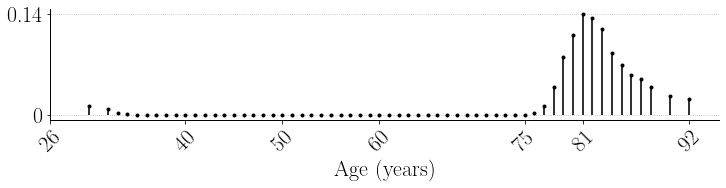

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pickle

# --- 1. Compact Style Setup (JRSSB / Tufte Style) ---
plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'font.size': 10,
    'axes.linewidth': 1.0,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 72,         # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

x_y_labels_fontsize = 22

def plot_posterior_compact(unique_ages, posterior, output_path=None):
    """
    Generates a minimalist stem plot suitable for JRSSB.
    Includes robust NaN handling.
    """
    # --- Data Cleaning ---
    # 1. Flatten to ensuring 1D arrays
    ages = np.array(unique_ages).flatten()
    probs = np.array(posterior).flatten()
    
    # 2. Create a mask to keep only Finite values (removes NaN and Inf)
    # We check both arrays to ensure alignment is preserved
    mask = np.isfinite(ages) & np.isfinite(probs)
    
    # 3. Apply mask
    ages = ages[mask]
    probs = probs[mask]
    
    if len(ages) == 0:
        print("Warning: No valid data points found (all inputs were NaN/Inf).")
        return None, None

    # --- Plotting ---
    fig, ax = plt.subplots(figsize=(12, 2.0))
    
    # JRSSB Style: Black stems, no baseline
    markerline, stemlines, baseline = ax.stem(
        ages, probs,
        linefmt='k-', markerfmt='ko', basefmt=' ', 
    )
    
    # Fine-tune visual elements
    plt.setp(stemlines, linewidth=2.0, alpha=0.8)
    plt.setp(markerline, markersize=4, markeredgewidth=0)

    # --- Smart Ticks ---
    # Find peak (MAP estimate)
    max_idx = np.argmax(probs)
    max_age = ages[max_idx]
    max_prob = probs[max_idx]

    # Calculate integer boundaries safely
    min_age_scalar = int(np.floor(np.min(ages)))
    max_age_scalar = int(np.ceil(np.max(ages)))

    # Generate Decade ticks (e.g. 40, 50, 60...)
    # Ensure start is a multiple of 10
    start_decade = (min_age_scalar // 10 + 1) * 10
    if start_decade < max_age_scalar:
        decades = np.arange(start_decade, max_age_scalar, 10)
    else:
        decades = np.array([])

    # Define critical points (Min, Max, Peak, and 75 as requested)
    critical_points = np.array([min_age_scalar, max_age_scalar, max_age, 75])
    
    # Combine, unique, and sort ticks
    # Filter out ticks that might be outside the valid range due to float/int rounding
    all_ticks = np.unique(np.concatenate((decades, critical_points)))
    all_ticks = all_ticks[(all_ticks >= min_age_scalar) & (all_ticks <= max_age_scalar)]
    
    # ax.set_xticks(all_ticks)
    ax.set_xticks([26, 40, 50, 60, 75, 81, 92]) # Add minor ticks for the original specified ages
    
    # Y-axis: Minimalist (Zero and Peak only)
    ax.set_yticks([0, max_prob])
    ax.set_yticklabels(['0', f'{max_prob:.2f}']) 
    
    ax.tick_params(axis='x', rotation=45, labelsize=x_y_labels_fontsize)
    ax.tick_params(axis='y', labelsize=x_y_labels_fontsize)

    # --- Labels ---
    ax.set_xlabel(r'Age (years)', fontsize=x_y_labels_fontsize)
    # ax.set_ylabel(r'Posterior', fontsize=x_y_labels_fontsize)
    ax.grid(axis='y', linestyle=':', color='gray', alpha=0.6)

    if output_path:
        fig.savefig(output_path, bbox_inches='tight', transparent=True)
    
    return fig, ax




fig,ax=plot_posterior_compact(baseline['ages'],baseline['conditional'])
# Restore the previous conditional-plot limits, with age 26 at the left boundary.
ax.set_xlim(26, 95.1)
plt.show()

## 4. Paired ±10% and ±20% eigenvalue sensitivity
The baseline is unchanged. Only the eigenvalues are perturbed; all location-specific states are recomputed.

In [5]:
remaining=[levels for levels in product(LEVELS,repeat=2) if levels!=(1.,1.)]
records.update(compute_scenarios(data,remaining))
rows=[]
for (levels,power,seed),r in records.items():
    base=records[((1.,1.),power,seed)]
    rows.append({'lambda_1':f'{100*(levels[0]-1):+.0f}%'.replace('+0%','0%'),
        'lambda_2':f'{100*(levels[1]-1):+.0f}%'.replace('+0%','0%'),
        'Draws':2**power,'Seed':seed,'P(0 chgpts)':r['absence'],'P(1 chgpt)':r['presence'],
        'Conditional peak age':r['ages'][np.argmax(r['conditional'])],
        'Conditional mass above 55':r['conditional'][r['ages']>55].sum(),
        'Conditional TV vs baseline':.5*np.abs(r['conditional']-base['conditional']).sum(),
        'Max. state residual':r['residuals'].max()})
summary=pd.DataFrame(rows).sort_values(['Draws','lambda_1','lambda_2'])
np.testing.assert_allclose(summary['P(0 chgpts)']+summary['P(1 chgpt)'],1,atol=1e-12)
summary.to_csv(data['root']/'sensitivity_summary_1024.csv',index=False)
level_order=['-20%','-10%','0%','+10%','+20%']
for power,seed in REPORT_CHECKS:
    print(f'{2**power} draws, seed {seed}: P(1 chgpt)')
    table=summary[summary.Draws==2**power].pivot(index='lambda_1',columns='lambda_2',values='P(1 chgpt)').reindex(index=level_order,columns=level_order)
    display(table.style.format('{:.6f}'))
print('All sensitivity and numerical diagnostics:');display(summary)


1024 draws, seed 123: P(1 chgpt)


lambda_2,-20%,-10%,0%,+10%,+20%
lambda_1,,,,,
-20%,0.410819,0.999997,1.000000,1.000000,1.000000
-10%,0.435770,0.445516,0.999997,1.000000,1.000000
0%,0.472793,0.474824,0.482719,0.999996,1.000000
+10%,0.511435,0.513450,0.515454,0.521857,0.999995
+20%,0.551159,0.553144,0.555114,0.557075,0.562279


All sensitivity and numerical diagnostics:


,lambda_1,lambda_2,Draws,Seed,P(0 chgpts),P(1 chgpt),Conditional peak age,Conditional mass above 55,Conditional TV vs baseline,Max. state residual
18,+10%,+10%,1024,123,4.781427e-01,0.521857,81.0,9.825026e-01,0.025351,1.114275e-09
19,+10%,+20%,1024,123,4.626824e-06,0.999995,30.0,5.001251e-06,0.976739,1.123297e-09
16,+10%,-10%,1024,123,4.865498e-01,0.513450,81.0,1.000000e+00,0.037109,1.108911e-09
15,+10%,-20%,1024,123,4.885650e-01,0.511435,81.0,1.000000e+00,0.037551,1.129025e-09
17,+10%,0%,1024,123,4.845457e-01,0.515454,81.0,1.000000e+00,0.037307,1.125088e-09
23,+20%,+10%,1024,123,4.429254e-01,0.557075,81.0,1.000000e+00,0.057809,1.105940e-09
24,+20%,+20%,1024,123,4.377210e-01,0.562279,81.0,9.868879e-01,0.049018,1.110293e-09
21,+20%,-10%,1024,123,4.468564e-01,0.553144,81.0,1.000000e+00,0.056972,1.120852e-09
20,+20%,-20%,1024,123,4.488407e-01,0.551159,81.0,1.000000e+00,0.057186,1.116523e-09
22,+20%,0%,1024,123,4.448859e-01,0.555114,81.0,1.000000e+00,0.057157,1.127047e-09


## 5. Conditional posterior sensitivity — original panel format, expanded to 5×5

Conditional on 1 change point: 1024 draws, seed 123


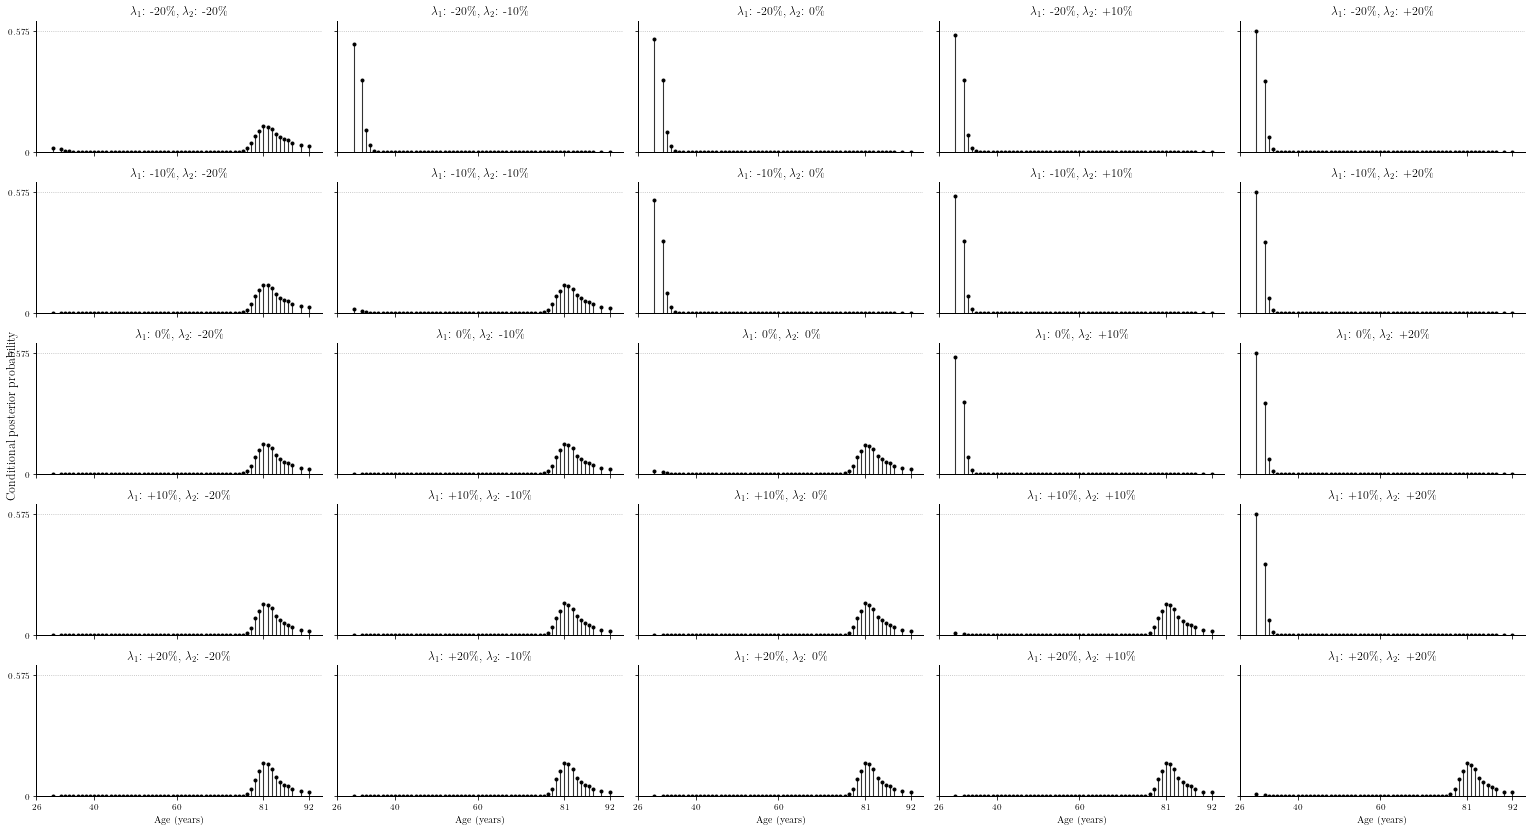

Completed fresh rank-3 reproduction and sensitivity analysis.


In [6]:
def plot_sensitivity(field, ylabel):
    fig, axes = plt.subplots(5, 5, figsize=(13*5/3, 7*5/3), sharex=True, sharey=True)
    finite = np.isfinite(ages)
    ymax = max(result[field][finite].max() for result in scenarios.values())
    for row, level_1 in enumerate(level_order):
        for col, level_2 in enumerate(level_order):
            ax = axes[row, col]
            values = scenarios[(level_1, level_2)][field]
            ax.vlines(ages[finite], 0, values[finite], color='black', linewidth=1.1, alpha=0.8)
            ax.plot(ages[finite], values[finite], 'ko', markersize=3)
            ax.set_title(r'$\lambda_1$: '+level_1.replace('%', r'\%')+r', $\lambda_2$: '+level_2.replace('%', r'\%'))
            ax.set_ylim(0, 1.08*ymax)
            ax.set_xticks([26, 40, 60, 81, 92])
            ax.set_yticks([0, ymax])
            ax.set_yticklabels(['0', f'{ymax:.3f}'])
            ax.grid(axis='y', linestyle=':', color='gray', alpha=0.6)
            if row == 4: ax.set_xlabel('Age (years)')
    fig.supylabel(ylabel)
    fig.tight_layout()
    plt.show()


ages=baseline['ages']
for power,seed in REPORT_CHECKS:
    print(f'Conditional on 1 change point: {2**power} draws, seed {seed}')
    scenarios={(level_order[i],level_order[j]):records[((u,v),power,seed)]
        for i,u in enumerate(LEVELS) for j,v in enumerate(LEVELS)}
    plot_sensitivity('conditional','Conditional posterior probability')
print('Completed fresh rank-3 reproduction and sensitivity analysis.')


## Explicit accuracy diagnostics: rho estimation versus posterior numerics

Three distinct quantities must not be conflated: **(i)** the signal-strength
moment-equation mismatch; **(ii)** numerical accuracy of posterior evaluation at
the chosen rho; **(iii)** statistical accuracy/calibration, which is not measured
by either diagnostic. The calculations below use saved fits/states; only the
one-dimensional likelihood quadrature is reevaluated at a finer order.


In [7]:

import numpy as np
import pandas as pd
import pickle
from IPython.display import display, Markdown
from tools.myocardial_final_redo import (empirical_adjustment, pilot,
    squared_logistic_state, gaussian_logistic_loglikelihood, normalize_posterior)
diagnostic_root=data['root']
X,y,phi=data['X'],data['y'],data['phi']
n,p=X.shape
B_aux=np.column_stack([np.linalg.lstsq(X*np.sqrt(w[:,None]),y*np.sqrt(w),rcond=None)[0] for w in phi])
theta_aux=X@B_aux
V_aux,_=empirical_adjustment(theta_aux,y,phi,n/p,loss='squared')
_,psi_aux=pilot(theta_aux,y,data['eta'],'squared')
observed_moment=V_aux.T@V_aux/n
predicted_moment=squared_logistic_state(data['rho'],phi,psi_aux,n/p)['moment']
rho_residual=np.linalg.norm(predicted_moment-observed_moment,'fro')
relative_rho_residual=rho_residual/np.linalg.norm(observed_moment,'fro')
np.testing.assert_allclose(rho_residual,data['trajectory'][-1]['moment_residual'],rtol=1e-10)
print('Inferred rho_hat (20 updates):')
display(pd.DataFrame(data['rho'],index=['Signal 1','Signal 2'],columns=['Signal 1','Signal 2']).style.format('{:.12f}'))
rho_diagnostics=pd.DataFrame([{
    'Absolute moment residual (Frobenius norm)':rho_residual,
    'Observed moment Frobenius norm':np.linalg.norm(observed_moment,'fro'),
    'Relative moment residual':relative_rho_residual,
    'Last rho update Frobenius norm':np.linalg.norm(data['trajectory'][-1]['rho']-data['trajectory'][-2]['rho']),
    'Smallest rho eigenvalue':np.linalg.eigvalsh(data['rho'])[0]}])
display(rho_diagnostics.T.rename(columns={0:'Value'}).style.format('{:.9g}'))
print('Observed and model-predicted second moments:')
display(pd.DataFrame(observed_moment));display(pd.DataFrame(predicted_moment))
display(Markdown(
    r'The diagnostic is $|\Lambda^T\hat\rho\Lambda+K-S\|_F$, with $S=V_{aux}^TV_{aux}/n$. '
    f'Its value is **{rho_residual:.6f}**, or **{100*relative_rho_residual:.2f}%** of '+
    r'$\|S\|_F$. This is **not** $\|\hat\rho-\rho_{true}\|$, a confidence interval, or a percentage accuracy of rho. '+
    'The true signal strength is unknown. This is a deliberately finite-iteration, constrained heuristic—not a certified moment-equation solution.'))
print('Last five rho updates (moment residual):')
display(pd.DataFrame([{'Update':r['iteration'],'Moment residual':r['moment_residual']} for r in data['trajectory'][-5:]]))
display(Markdown('Both estimated eigenvalues are equal. The ±10%/±20% analysis holds the coordinate eigenbasis fixed; separate eigenvalue perturbations are basis-dependent at this repeated eigenvalue.'))
rho_diagnostics.to_csv(diagnostic_root/'rho_accuracy_diagnostics.csv',index=False)


Inferred rho_hat (20 updates):


,Signal 1,Signal 2
Signal 1,0.003270894818,0.000000000000
Signal 2,0.000000000000,0.003270894818


,Value
Absolute moment residual (Frobenius norm),0.0131663265
Observed moment Frobenius norm,0.0580486889
Relative moment residual,0.226815226
Last rho update Frobenius norm,0.00149477415
Smallest rho eigenvalue,0.00327089482


Observed and model-predicted second moments:


,0,1
0,0.026528,0.027607
1,0.027607,0.033787


,0,1
0,0.035404,0.033391
1,0.033391,0.039046


The diagnostic is $|\Lambda^T\hat\rho\Lambda+K-S\|_F$, with $S=V_{aux}^TV_{aux}/n$. Its value is **0.013166**, or **22.68%** of $\|S\|_F$. This is **not** $\|\hat\rho-\rho_{true}\|$, a confidence interval, or a percentage accuracy of rho. The true signal strength is unknown. This is a deliberately finite-iteration, constrained heuristic—not a certified moment-equation solution.

Last five rho updates (moment residual):


,Update,Moment residual
0,16,0.013583
1,17,0.013431
2,18,0.013317
3,19,0.013231
4,20,0.013166


Both estimated eigenvalues are equal. The ±10%/±20% analysis holds the coordinate eigenbasis fixed; separate eigenvalue perturbations are basis-dependent at this repeated eigenvalue.

In [8]:

checks=[pickle.load((diagnostic_root/'scenario_100_100_q10_seed123.pkl').open('rb'))]
reported=checks[0]
numerical_diagnostics=pd.DataFrame([{
    'QMC draws':1024,'Seed':123,
    'P(0 chgpts)':reported['absence'],'P(1 chgpt)':reported['presence'],
    'Max sampled-state equation residual':reported['residuals'].max(),
    'Posterior normalization discrepancy':abs(reported['probabilities'].sum()-1),
    'Conditional normalization discrepancy':abs(reported['conditional'].sum()-1),
    'Conditional posterior mode (age)':reported['ages'][np.argmax(reported['conditional'])]}])
display(numerical_diagnostics.T.rename(columns={0:'Value'}).style.format('{:.9g}'))
display(Markdown(
    'All reported results use **1,024 scrambled-Sobol draws, seed 123**. '
    'The approximately 1e-9 state residual measures agreement with the sampled equations, '
    '**not** integration error, exact population-equation error, or statistical calibration. '
    'A single reported QMC setting does not provide a Monte Carlo standard error or confidence interval.'))
numerical_diagnostics.to_csv(diagnostic_root/'posterior_numerical_diagnostics_1024.csv',index=False)


,Value
QMC draws,1024
Seed,123
P(0 chgpts),0.517280957
P(1 chgpt),0.482719043
Max sampled-state equation residual,1.107784e-09
Posterior normalization discrepancy,6.80788759e-13
Conditional normalization discrepancy,1.27897692e-12
Conditional posterior mode (age),81


All reported results use **1,024 scrambled-Sobol draws, seed 123**. The approximately 1e-9 state residual measures agreement with the sampled equations, **not** integration error, exact population-equation error, or statistical calibration. A single reported QMC setting does not provide a Monte Carlo standard error or confidence interval.

In [9]:

# Quadrature-only check: freeze each saved state and double the Gaussian
# quadrature order from 160 to 320. This does NOT refit or re-estimate rho.
quadrature_rows=[]
for (power,seed),baseline_result in zip(((10,123),),checks):
    likelihoods=[]
    for index,e in enumerate(data['eta']):
        state=pickle.load((diagnostic_root/f'eig100_100_q{power}_seed{seed}_location{index}.pkl').open('rb'))['state']
        psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
        likelihoods.append(gaussian_logistic_loglikelihood(data['fit']['V'],y,data['rho'],
            state['lambda'],state['kappa'],psi,quadrature_order=320))
    refined=normalize_posterior(likelihoods,data['prior'])
    quadrature_rows.append({'QMC draws':2**power,'Seed':seed,
        'P(1), quadrature 160':baseline_result['presence'],
        'P(1), quadrature 320':refined['presence'],
        'Absolute P(1) difference':abs(refined['presence']-baseline_result['presence']),
        'Conditional TV difference':.5*np.abs(refined['conditional']-baseline_result['conditional']).sum(),
        'Max absolute log-likelihood difference':np.max(np.abs(np.asarray(likelihoods)-baseline_result['log_likelihood']))})
quadrature_diagnostics=pd.DataFrame(quadrature_rows)
print('Independent error-source check: likelihood quadrature order 160 versus 320')
display(quadrature_diagnostics.style.format(precision=10))
quadrature_diagnostics.to_csv(diagnostic_root/'likelihood_quadrature_diagnostics_1024.csv',index=False)
display(Markdown(
    '**Bottom line:** report the moment residual and numerical differences separately. '+
    'The quadrature comparison isolates likelihood-integration sensitivity with the 1,024-draw states held fixed; it is not an overall posterior error bound. '+
    'The much larger changes under rho perturbation in the sensitivity section are a separate limitation. '+
    'These diagnostics support transparency and numerical reproducibility, **not a claim of accurate signal-strength estimation or calibrated change-point probabilities**.'))


Independent error-source check: likelihood quadrature order 160 versus 320


,QMC draws,Seed,"P(1), quadrature 160","P(1), quadrature 320",Absolute P(1) difference,Conditional TV difference,Max absolute log-likelihood difference
0,1024,123,0.4827190435,0.4827190435,0.0000000000,0.0000000000,0.0000000000


**Bottom line:** report the moment residual and numerical differences separately. The quadrature comparison isolates likelihood-integration sensitivity with the 1,024-draw states held fixed; it is not an overall posterior error bound. The much larger changes under rho perturbation in the sensitivity section are a separate limitation. These diagnostics support transparency and numerical reproducibility, **not a claim of accurate signal-strength estimation or calibrated change-point probabilities**.